In [5]:
%pip install -q ultralytics

Note: you may need to restart the kernel to use updated packages.


In [13]:
import os
import torch
import torchvision
import ultralytics
from pathlib import Path

# Dataset location
DATASET_DIR = Path("/kaggle/input/datasets/bhoomi0805/yyoollo")

# Project working directory
PROJECT_DIR = Path("/kaggle/working/Tomato_Object_Detection")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 55)
print("YOLO OBJECT DETECTION - ENVIRONMENT CHECK")
print("=" * 55)

print("\nPYTHON ENVIRONMENT")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Ultralytics:", ultralytics.__version__)

print("\nGPU INFORMATION")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

print("\nDATASET")
print("Dataset exists:", DATASET_DIR.exists())

print("\nPROJECT DIRECTORY")
print("Project directory:", PROJECT_DIR)
print("Directory ready:", PROJECT_DIR.exists())

print("\nENVIRONMENT CHECK COMPLETED")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO OBJECT DETECTION - ENVIRONMENT CHECK

PYTHON ENVIRONMENT
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Ultralytics: 8.4.215

GPU INFORMATION
CUDA available: False

DATASET
Dataset exists: True

PROJECT DIRECTORY
Project directory: /kaggle/working/Tomato_Object_Detection
Directory ready: True

ENVIRONMENT CHECK COMPLETED


In [14]:
import shutil
import yaml
from pathlib import Path

DATASET_DIR = Path("/kaggle/input/datasets/bhoomi0805/yyoollo")
YAML_PATH = DATASET_DIR / "valid" / "data.yaml"
PROJECT_DIR = Path("/kaggle/working/Tomato_Object_Detection")

# Storage information
total, used, free = shutil.disk_usage("/kaggle/working")

print("STORAGE INFORMATION")
print(f"Total: {total / (1024**3):.2f} GB")
print(f"Used: {used / (1024**3):.2f} GB")
print(f"Free: {free / (1024**3):.2f} GB")

# Dataset configuration
with open(YAML_PATH, "r") as f:
    config = yaml.safe_load(f)

print("\nDATASET CONFIGURATION")
print("Number of classes:", config["nc"])
print("Class names:", config["names"])

print("\nDATASET SPLITS")
for split in ["train", "val", "test"]:
    path = (YAML_PATH.parent / config[split]).resolve()
    print(f"{split}: {path.exists()}")

# Original dataset license information
print("\nLICENSE FILES")
for filename in ["README.dataset.txt", "README.roboflow.txt"]:
    path = DATASET_DIR / filename
    print(f"\n{filename}:")
    print(path.read_text()[:1500] if path.exists() else "Not found")

STORAGE INFORMATION
Total: 19.52 GB
Used: 0.00 GB
Free: 19.50 GB

DATASET CONFIGURATION
Number of classes: 10
Class names: ['Bacterial_spot', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Septoria_leaf_spot', 'Spider_mites Two-spotted_spider_mite', 'Target_Spot', 'Tomato_Yellow_Leaf_Curl_Virus', 'Tomato__healthy', 'Tomato_mosaic_virus']

DATASET SPLITS
train: True
val: True
test: True

LICENSE FILES

README.dataset.txt:
# tomato leaf detection > Tomato_BBox_v1
https://universe.roboflow.com/quynh-nguyen-tnu6q/tomato-leaf-detection-u6mou-iisg2

Provided by a Roboflow user
License: CC BY 4.0



README.roboflow.txt:

tomato leaf detection - v1 Tomato_BBox_v1

This dataset was exported via roboflow.com on September 11, 2026 at 6:32 PM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and depl

In [15]:
from pathlib import Path

DATASET_DIR = Path("/kaggle/input/datasets/bhoomi0805/yyoollo")

total_size = 0

for file in DATASET_DIR.rglob("*"):
    if file.is_file():
        total_size += file.stat().st_size

print("DATASET SIZE:", round(total_size / (1024**3), 2), "GB")

duplicate_train = DATASET_DIR / "train/images/329f2f31-ceca-402f-a007-21d64fe75f5e___Crnl_L-Mold-6519_JPG.rf.01124f1644553f455d219f6e0a188726.jpg"

duplicate_valid = DATASET_DIR / "valid/images/Tomato___Leaf_Mold_original_329f2f31-ceca-402f-a007-21d64fe75f5e___Crnl_L-Mold-6519-JPG_218cd357-e5b1-48a3-9ddc-7595bb14ea6c_JPG.rf.f6c141b16904f61c9e4c7b865da7831a.jpg"

print("\nDUPLICATE VERIFICATION")
print("Train image exists:", duplicate_train.exists())
print("Validation image exists:", duplicate_valid.exists())

print("\nAVAILABLE WORKING STORAGE: 19.50 GB")
print("SIZE CHECK COMPLETED")

DATASET SIZE: 0.16 GB

DUPLICATE VERIFICATION
Train image exists: True
Validation image exists: True

AVAILABLE WORKING STORAGE: 19.50 GB
SIZE CHECK COMPLETED


In [1]:
from pathlib import Path
import os
import yaml

SOURCE = Path("/kaggle/input/datasets/bhoomi0805/yyoollo")
PROJECT = Path("/kaggle/working/Tomato_Object_Detection")
CLEAN = PROJECT / "dataset"

# Duplicate image to exclude from validation
duplicate_name = (
    "Tomato___Leaf_Mold_original_329f2f31-ceca-402f-a007-21d64fe75f5e"
    "___Crnl_L-Mold-6519-JPG_218cd357-e5b1-48a3-9ddc-7595bb14ea6c"
    "_JPG.rf.f6c141b16904f61c9e4c7b865da7831a.jpg"
)

# Create clean directory structure using symbolic links
for split in ["train", "valid", "test"]:
    for folder in ["images", "labels"]:
        source_folder = SOURCE / split / folder
        target_folder = CLEAN / split / folder
        target_folder.mkdir(parents=True, exist_ok=True)

        for file in source_folder.iterdir():
            if not file.is_file():
                continue

            # Exclude the validation duplicate and its matching label
            if split == "valid" and file.stem == Path(duplicate_name).stem:
                continue

            target_file = target_folder / file.name

            if not target_file.exists():
                target_file.symlink_to(file)

# Create a clean YAML configuration
original_yaml = yaml.safe_load(
    (SOURCE / "valid/data.yaml").read_text()
)

clean_yaml = {
    "path": str(CLEAN),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": original_yaml["nc"],
    "names": original_yaml["names"]
}

yaml_path = CLEAN / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(clean_yaml, f, sort_keys=False)

# Verify the working dataset
print("CLEAN DATASET CREATED\n")

for split in ["train", "valid", "test"]:
    images = list((CLEAN / split / "images").glob("*"))
    labels = list((CLEAN / split / "labels").glob("*.txt"))

    print(f"{split.upper()}:")
    print("Images:", len(images))
    print("Labels:", len(labels))

print("\nDuplicate excluded from validation:",
      not (CLEAN / "valid/images" / duplicate_name).exists())

print("YAML created:", yaml_path.exists())
print("YAML path:", yaml_path)

CLEAN DATASET CREATED

TRAIN:
Images: 6928
Labels: 6928
VALID:
Images: 1969
Labels: 1969
TEST:
Images: 997
Labels: 997

Duplicate excluded from validation: True
YAML created: True
YAML path: /kaggle/working/Tomato_Object_Detection/dataset/data.yaml


In [17]:
from ultralytics import YOLO
model = YOLO("yolo11n.pt")
print("YOLO11n model loaded successfully!")

YOLO11n model loaded successfully!


In [2]:
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU Available: True
GPU: Tesla T4


In [6]:
from ultralytics import YOLO
model = YOLO("yolo11n.pt")
print("YOLO11n loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO11n loaded successfully!


In [7]:
results = model.train(
    data="/kaggle/working/Tomato_Object_Detection/dataset/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    patience=10,
    device=0,
    workers=2,
    seed=42,
    project="/kaggle/working/Tomato_Object_Detection",
    name="YOLO11n_Tomato_Detection",
    exist_ok=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Tomato_Object_Detection/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n_Tomato_Detection, nbs=6

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      2.76G     0.6498     0.9792      1.259         40        640: 100% ━━━━━━━━━━━━ 433/433 8.2it/s 53.1s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 5.8it/s 10.7s0.2s
                   all       1969       1969      0.653      0.734      0.789       0.61

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.76G     0.6503     0.9138      1.255         40        640: 100% ━━━━━━━━━━━━ 433/433 8.2it/s 53.1s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 6.0it/s 10.4s0.2s
                   all       1969       1969      0.742      0.827       0.88      0.673

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.76G     0.6369     0.8501      1.245         50        640: 100% ━━━━━━━━━━━━ 433/433 8.1it/s 53.2s0.1ss
                 Class     I

In [8]:
from ultralytics import YOLO

best_model = YOLO(
    "/kaggle/working/Tomato_Object_Detection/YOLO11n_Tomato_Detection/weights/best.pt"
)

test_results = best_model.val(
    data="/kaggle/working/Tomato_Object_Detection/dataset/data.yaml",
    split="test",
    device=0
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.3±0.0 ms, read: 0.2±0.1 MB/s, size: 17.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/working/Tomato_Object_Detection/dataset/test/labels... 997 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 997/997 17.0it/s 58.5s0.1ss
val: New cache created: /kaggle/working/Tomato_Object_Detection/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 6.4it/s 9.8s0.1s
                   all        997        998      0.996      0.992      0.994      0.946
        Bacterial_spot        103        103          1      0.974      0.995      0.966
          Early_blight         94      

confusion_matrix.png


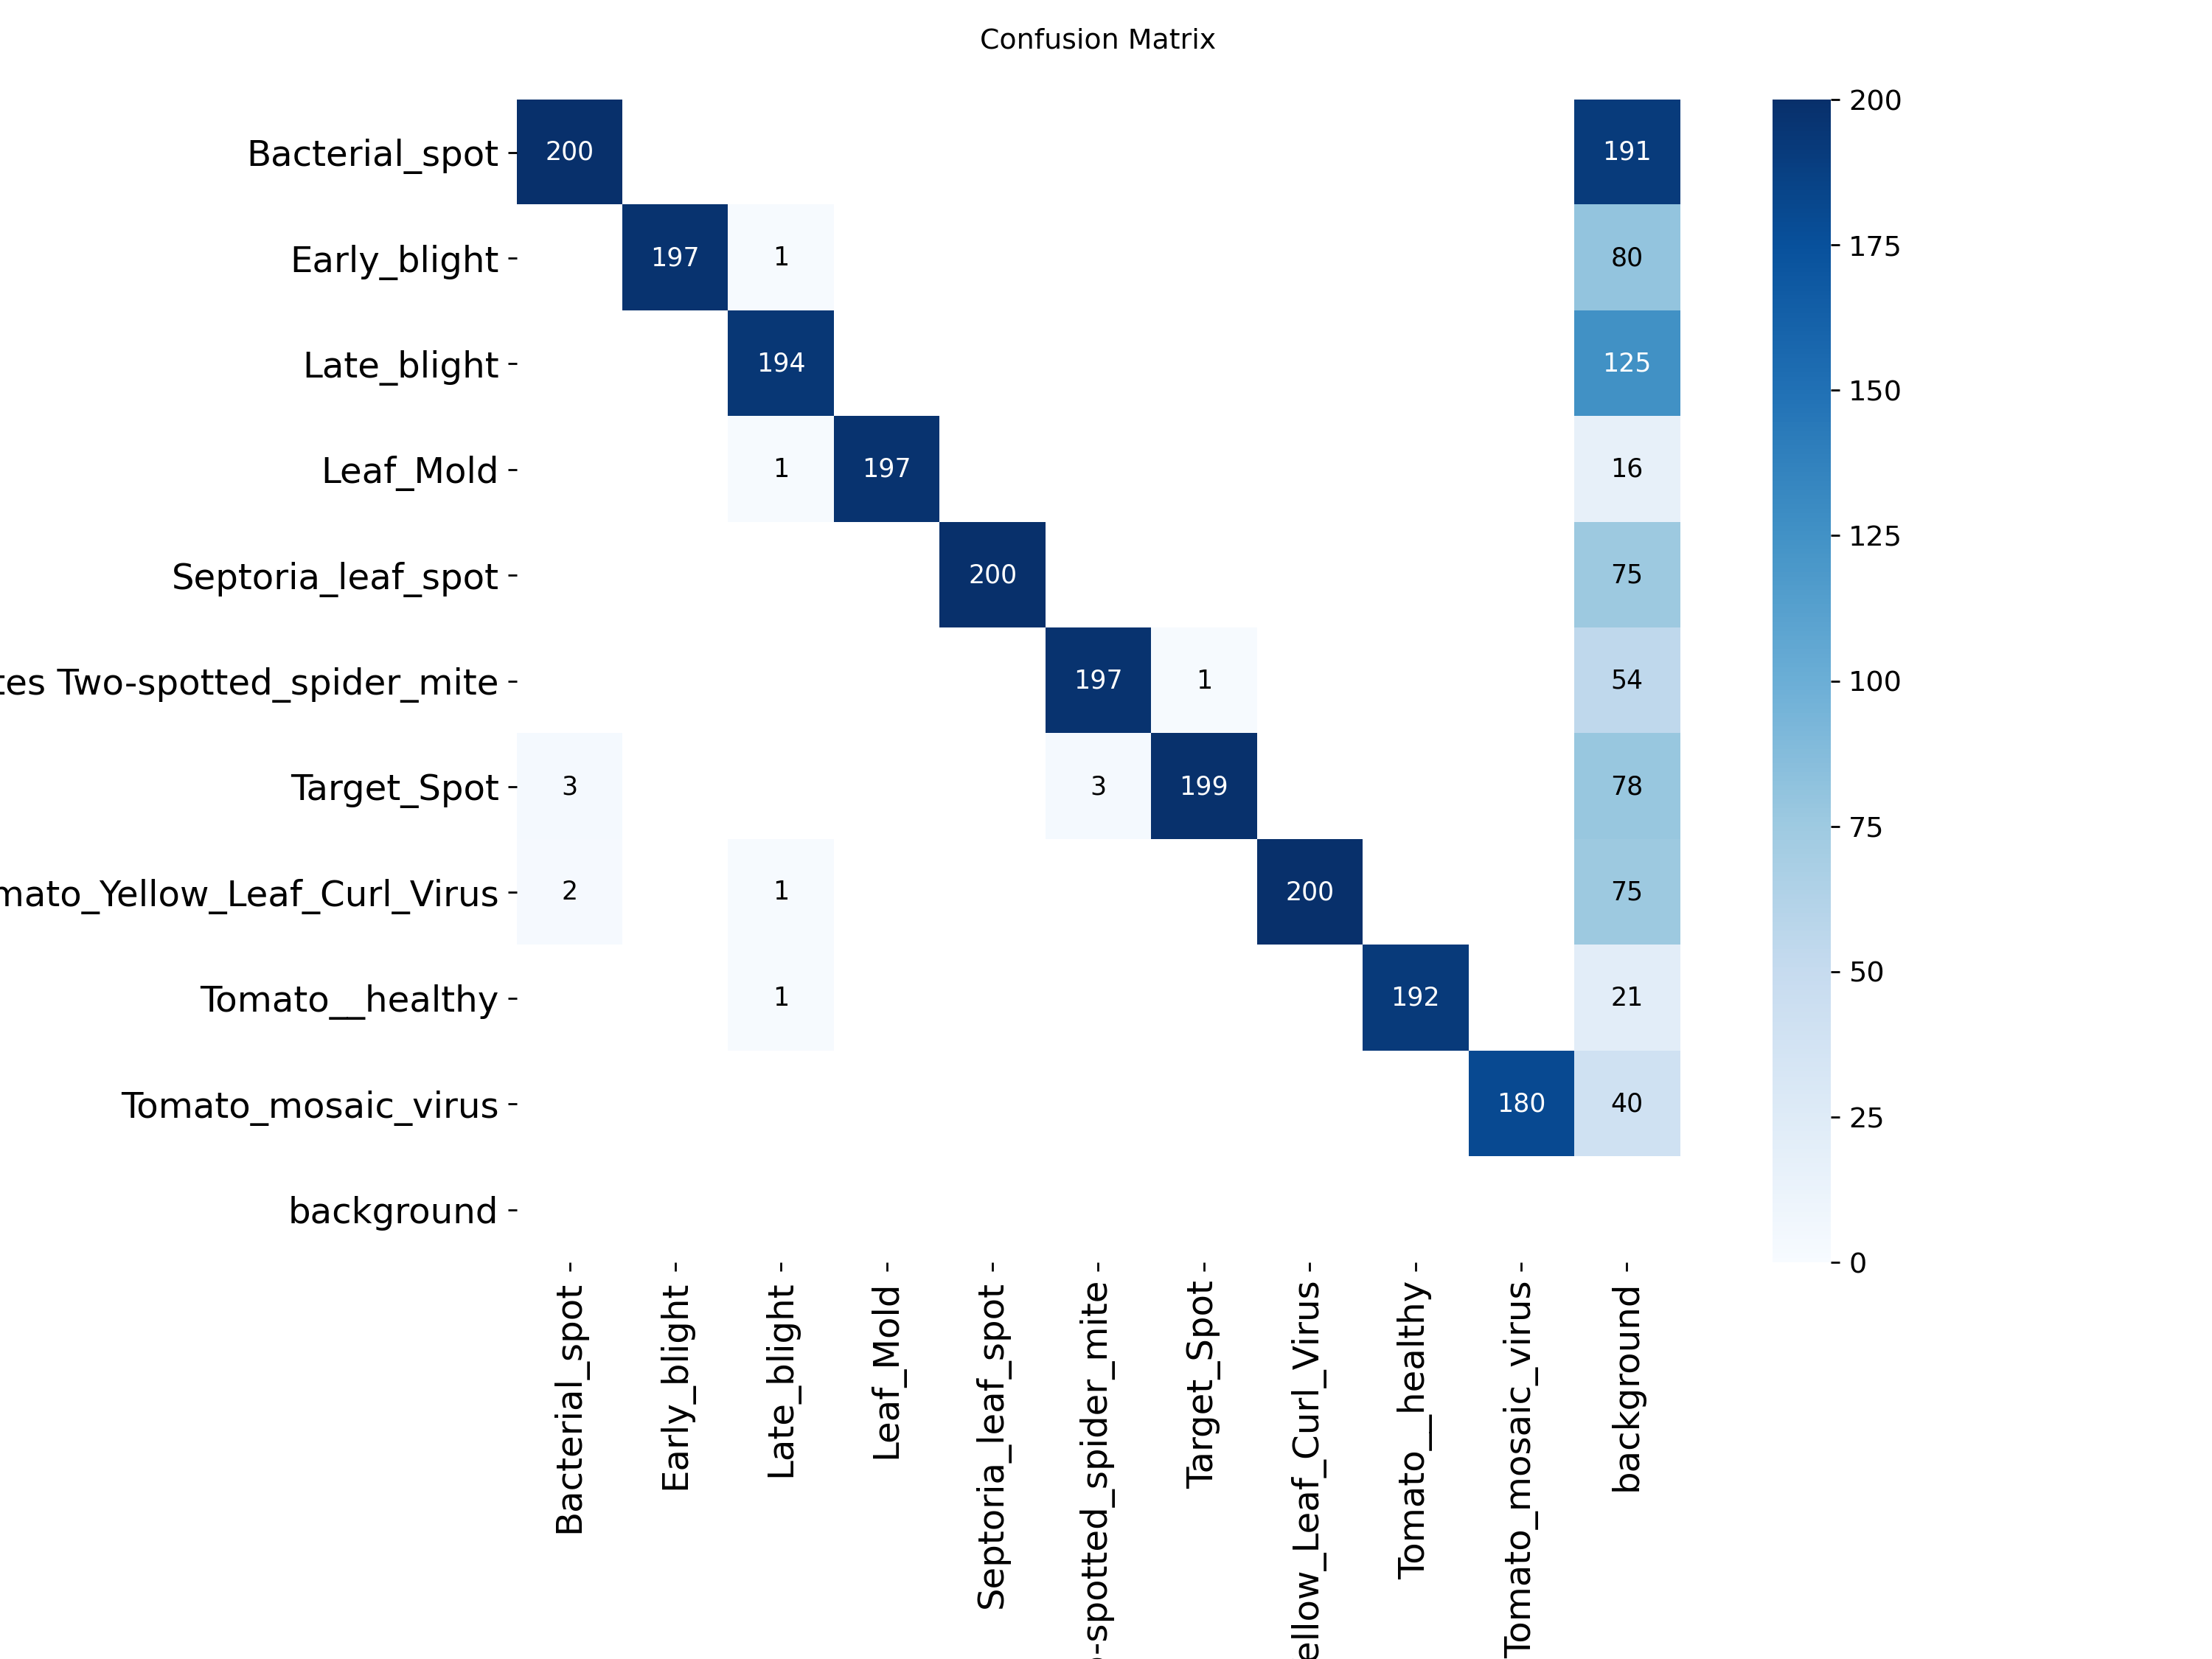

results.png


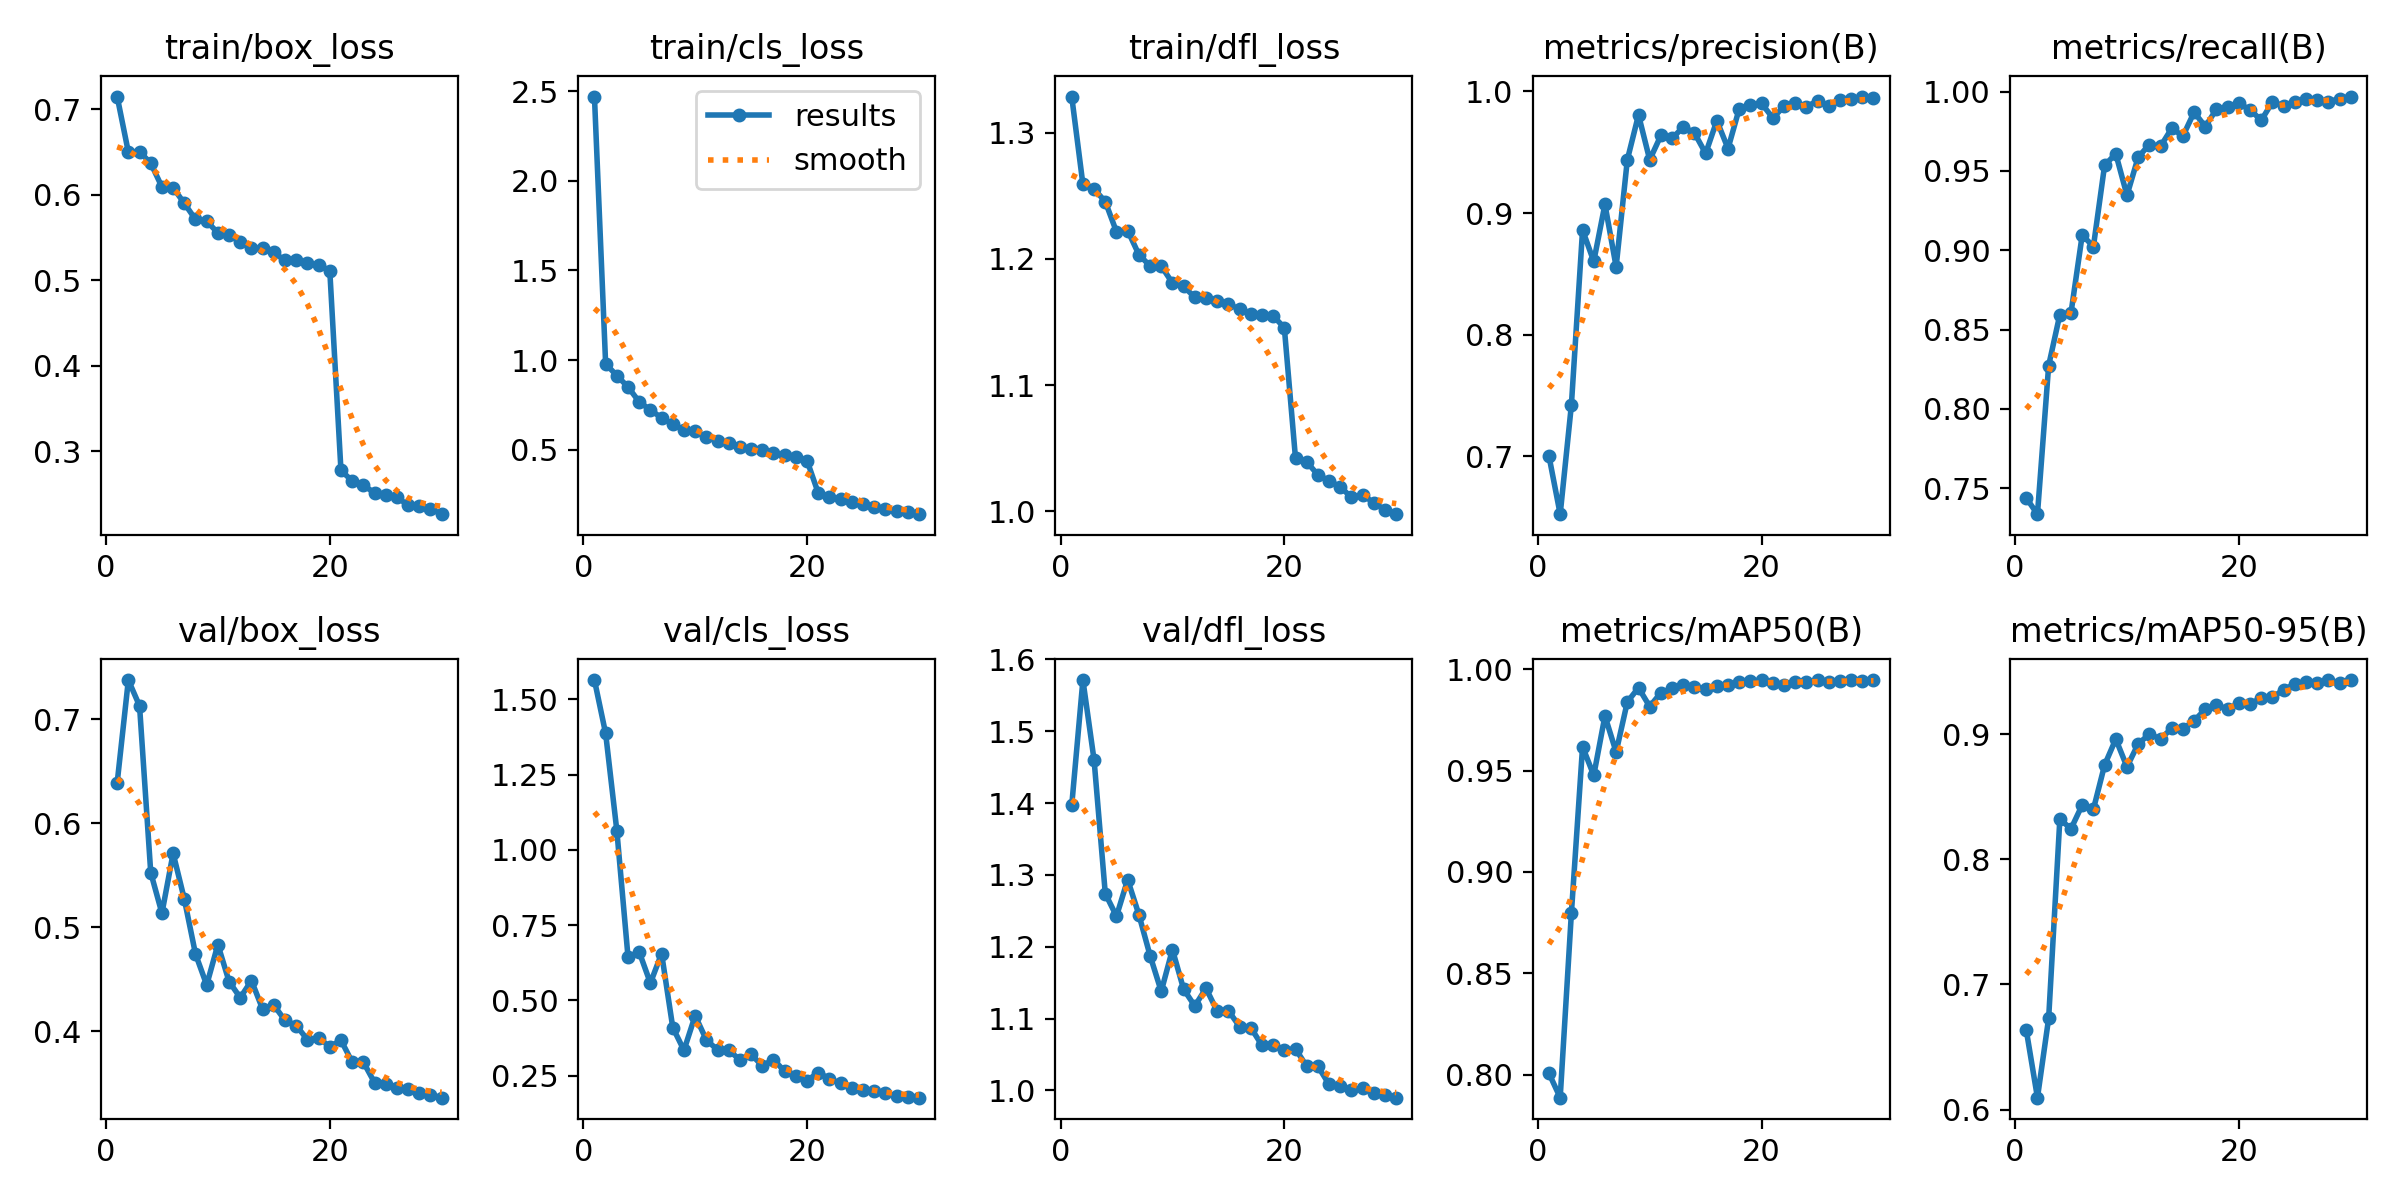

In [9]:
from pathlib import Path
from IPython.display import display, Image

RESULTS = Path(
    "/kaggle/working/Tomato_Object_Detection/YOLO11n_Tomato_Detection"
)

for filename in ["confusion_matrix.png", "results.png"]:
    path = RESULTS / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))

In [10]:
predictions = best_model.predict(
    source="/kaggle/working/Tomato_Object_Detection/dataset/test/images",
    save=True,
    conf=0.25,
    device=0
)

print("Prediction images generated successfully!")


image 1/997 /kaggle/working/Tomato_Object_Detection/dataset/test/images/021accd9-bbb2-4777-8f94-93295e6de49e___PSU_CG-2075_JPG.rf.858aa8b9215828caec030db9d16e1a82.jpg: 640x640 1 Tomato_mosaic_virus, 10.8ms
image 2/997 /kaggle/working/Tomato_Object_Detection/dataset/test/images/023fe2d4-6e1d-40ce-99ae-85ba90f436ff___RS_Erly-B-6354_JPG.rf.a575eab44f1d3a5e059e7f77effff9ee.jpg: 640x640 1 Early_blight, 12.5ms
image 3/997 /kaggle/working/Tomato_Object_Detection/dataset/test/images/0288164e-d6cf-4215-b593-7b581308a4cf___Com-G_TgS_FL-9777_JPG.rf.7e0c8776d58b2c561df72c78775e71b2.jpg: 640x640 1 Target_Spot, 10.9ms
image 4/997 /kaggle/working/Tomato_Object_Detection/dataset/test/images/036d12b0-1e97-4975-bd80-a8a3c48588e7___Crnl_L-Mold-6500_JPG.rf.307c6b04f64c9c34b40e64d916e503f3.jpg: 640x640 1 Leaf_Mold, 10.9ms
image 5/997 /kaggle/working/Tomato_Object_Detection/dataset/test/images/0372686b-04b2-4a25-98da-5801747fa1af___RS_HL-0391_JPG.rf.16f92a91888af56a6f3d5d3b6463cb91.jpg: 640x640 1 Tomato__h

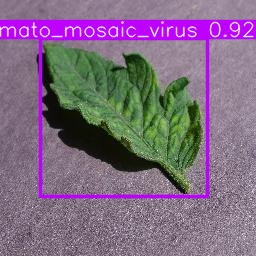

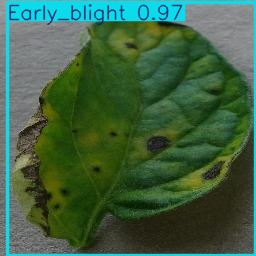

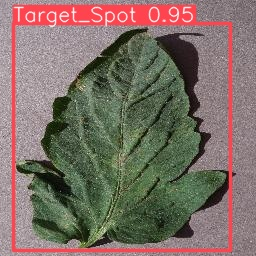

In [11]:
from pathlib import Path
from IPython.display import display, Image

PRED_DIR = Path("/kaggle/working/runs/detect/predict")

images = sorted(PRED_DIR.glob("*.jpg"))[:3]

for img in images:
    display(Image(filename=str(img)))

In [12]:
from pathlib import Path
import shutil

best_model_path = Path(
    "/kaggle/working/Tomato_Object_Detection/YOLO11n_Tomato_Detection/weights/best.pt"
)

output_path = Path("/kaggle/working/best_tomato_detection.pt")

shutil.copy2(best_model_path, output_path)

print("FINAL DETECTION MODEL SAVED!")
print("Path:", output_path)
print("Model size:", round(output_path.stat().st_size / (1024 * 1024), 2), "MB")

FINAL DETECTION MODEL SAVED!
Path: /kaggle/working/best_tomato_detection.pt
Model size: 5.25 MB
